# Loading the CMS Upsilon Data and Computing Invariant Mass

This short notebook shows how to load the CMS Open Data Upsilon-to-dimuon candidate sample and compute the dimuon invariant mass from the two muon four-vectors. It is not a solution to the project fit; it only gets the data into a useful form.

## Relativistic Kinematics

CMS provides each muon's energy and three-momentum components. In units where $c=1$, write each muon four-vector as

$$p_i^\mu = (E_i, p_{x,i}, p_{y,i}, p_{z,i}).$$

The dimuon four-vector is the sum of the two muon four-vectors:

$$P^{\mu}_{\mu\mu} = p_1^\mu + p_2^\mu.$$

The invariant mass is the Minkowski norm of this total four-vector:

$$M_{\mu\mu}^2 = P^\mu P_\mu = (E_1 + E_2)^2 - (p_{x,1}+p_{x,2})^2 - (p_{y,1}+p_{y,2})^2 - (p_{z,1}+p_{z,2})^2.$$

The dimuon transverse momentum is also often useful:

$$p_{T,\mu\mu} = \sqrt{(p_{x,1}+p_{x,2})^2 + (p_{y,1}+p_{y,2})^2}.$$

The input energies and momenta are in GeV, so the reconstructed invariant mass is in GeV.

In [43]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from scipy.optimize import minimize
from scipy.special import erf
from scipy.stats import chi2


plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True})

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
FIGURE_DIR =  PROJECT_ROOT / "figures"
print(PROJECT_ROOT)
print(FIGURE_DIR)

c:\Users\nickk\OneDrive\Desktop\CompPhysGrad\ProjectI\project1-nkoval-wm
c:\Users\nickk\OneDrive\Desktop\CompPhysGrad\ProjectI\project1-nkoval-wm\figures


## Load the CSV

If the file is already present at `data/raw/Ymumu.csv`, this notebook uses the local copy. Otherwise it tries the direct CMS Open Data file URLs and saves the downloaded CSV locally. Do not commit downloaded data files.

In [44]:
if Path.cwd().name == "notebooks":
    repo_root = Path.cwd().parent
else:
    repo_root = Path.cwd()

data_dir = repo_root / "data" / "raw"
data_dir.mkdir(parents=True, exist_ok=True)
data_path = data_dir / "Ymumu.csv"

candidate_urls = [
    "https://opendata.cern.ch/record/5206/files/Ymumu.csv?download=1",
    "https://opendata.cern.ch/record/cms-5206/files/Ymumu.csv?download=1",
    "http://opendata.cern.ch/record/5206/files/Ymumu.csv?download=1",
    "http://cern.ch/opendata/record/5206/files/Ymumu.csv",
]

def load_upsilon_data(path=data_path):
    if path.exists():
        return pd.read_csv(path), str(path)

    errors = []
    for url in candidate_urls:
        try:
            table = pd.read_csv(url)
            if len(table) > 1000:
                table.to_csv(path, index=False)
                return table, url
        except Exception as exc:
            errors.append(f"{url}: {type(exc).__name__}: {exc}")

    raise FileNotFoundError(
        "Could not load the CMS Upsilon CSV automatically. Download it from "
        "https://opendata.cern.ch/record/cms-5206 and save it as "
        f"{path}. Tried:\n" + "\n".join(errors)
    )

events, source = load_upsilon_data()
print(f"Loaded {len(events):,} events from {source}")
events.head()

Loaded 20,000 events from c:\Users\nickk\OneDrive\Desktop\CompPhysGrad\ProjectI\project1-nkoval-wm\data\raw\Ymumu.csv


,Run,Event,type1,E1,px1,py1,pz1,pt1,eta1,phi1,Q1,type2,E2,px2,py2,pz2,pt2,eta2,phi2,Q2
0,165617,75100943,G,6.2039,-4.2666,0.4565,-4.4793,4.2910,-0.9121,3.0350,-1,G,9.6690,7.2740,-2.8211,-5.7104,7.8019,-0.6786,-0.3700,1
1,165617,75587682,G,19.2892,-4.2121,-0.6516,18.8121,4.2622,2.1905,-2.9881,-1,G,9.8244,4.3439,-0.4735,8.7985,4.3697,1.4497,-0.1086,1
2,165617,75167029,G,9.7583,2.3903,-3.7824,8.6715,4.4744,1.4156,-1.0072,-1,G,13.5684,-3.3975,5.1910,12.0665,6.2039,1.4187,2.1503,1
3,165617,75281957,G,9.6365,1.6516,-5.4313,7.7862,5.6769,1.1213,-1.2756,1,G,7.0263,-1.6449,4.4418,5.1887,4.7366,0.9473,1.9255,-1
4,165617,75393376,G,6.0112,3.3614,2.8883,4.0598,4.4318,0.8208,0.7098,-1,G,7.7557,-5.0416,-3.0126,5.0642,5.8731,0.7806,-2.6030,1


In [45]:
events.columns.tolist()

['Run',
 'Event',
 'type1',
 'E1',
 'px1',
 'py1',
 'pz1',
 'pt1',
 'eta1',
 'phi1',
 'Q1',
 'type2',
 'E2',
 'px2',
 'py2',
 'pz2',
 'pt2',
 'eta2',
 'phi2',
 'Q2']

## Compute the Dimuon Mass

The column names use `1` and `2` for the two muons. For example, `E1`, `px1`, `py1`, `pz1` are the energy and momentum components of the first muon.

In [46]:
required_columns = ["E1", "px1", "py1", "pz1", "E2", "px2", "py2", "pz2"]
missing_columns = [column for column in required_columns if column not in events.columns]
if missing_columns:
    raise ValueError(f"Missing required four-vector columns: {missing_columns}")

total_energy = events["E1"] + events["E2"]
total_px = events["px1"] + events["px2"]
total_py = events["py1"] + events["py2"]
total_pz = events["pz1"] + events["pz2"]

mass_squared = total_energy**2 - total_px**2 - total_py**2 - total_pz**2
events["M_recomputed"] = np.sqrt(np.clip(mass_squared, 0.0, None))
events["dimuon_pt"] = np.sqrt(total_px**2 + total_py**2)
events["sigma_P"] = np.sqrt(len(events["M_recomputed"]))

events[["E1", "px1", "py1", "pz1", "E2", "px2", "py2", "pz2", "M_recomputed", "dimuon_pt","sigma_P"]].head()

,E1,px1,py1,pz1,E2,px2,py2,pz2,M_recomputed,dimuon_pt,sigma_P
0,6.2039,-4.2666,0.4565,-4.4793,9.6690,7.2740,-2.8211,-5.7104,11.553492,3.825675,141.421356
1,19.2892,-4.2121,-0.6516,18.8121,9.8244,4.3439,-0.4735,8.7985,9.163692,1.132794,141.421356
2,9.7583,2.3903,-3.7824,8.6715,13.5684,-3.3975,5.1910,12.0665,10.539055,1.731648,141.421356
3,9.6365,1.6516,-5.4313,7.7862,7.0263,-1.6449,4.4418,5.1887,10.407772,0.989523,141.421356
4,6.0112,3.3614,2.8883,4.0598,7.7557,-5.0416,-3.0126,5.0642,10.170626,1.684792,141.421356


In [47]:
events["M_recomputed"].describe()

count    20000.000000
mean        10.212868
std          0.984798
min          8.001354
25%          9.451247
50%         10.162193
75%         11.017530
max         11.999706
Name: M_recomputed, dtype: float64

## First Sanity-Check Plot

This plot confirms that the sample is in the Upsilon mass region. The project analysis should go beyond this by choosing a model, fitting it, assessing uncertainties, and comparing models.

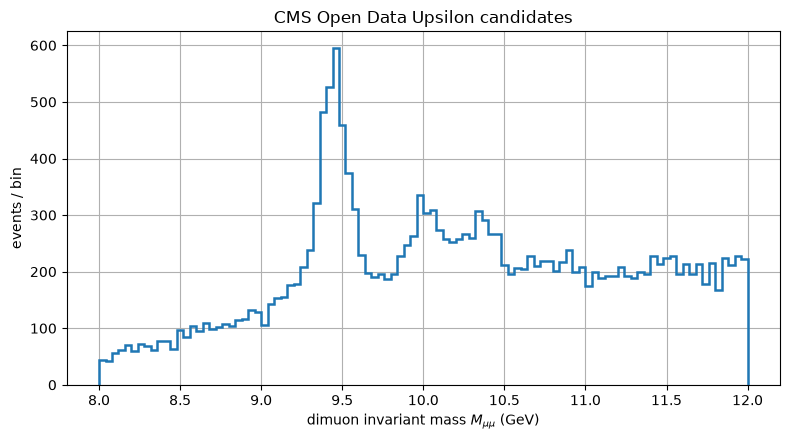

In [48]:
MASS_RANGE = (8.0,12.0)
fig, ax = plt.subplots()
ax.hist(events["M_recomputed"], bins=100, range=MASS_RANGE, histtype="step", lw=1.8)
ax.set_xlabel("dimuon invariant mass $M_{\\mu\\mu}$ (GeV)")
ax.set_ylabel("events / bin")
ax.set_title("CMS Open Data Upsilon candidates")
fig.tight_layout() 

At this point you have the key observable for the project. A clean next step is to decide on a binning, define a smooth background model, define three- and four-peak signal models, and compare them with a defensible uncertainty statement.

In [79]:
MASS_RANGE = (8.0, 12.0)

analysis_data = events.loc[
    events["M_recomputed"].between(MASS_RANGE[0], MASS_RANGE[1], inclusive="both")
].copy()


def normal_cdf(x, mean, sigma):
    """Evaluate the Gaussian cumulative distribution function."""
    return 0.5 * (1.0 + erf((x - mean) / (np.sqrt(2.0) * sigma)))


def truncated_gaussian_pdf(x, mean, sigma, lower, upper):
    """Gaussian PDF renormalized to integrate to one inside [lower, upper]."""
    normalization = normal_cdf(upper, mean, sigma) - normal_cdf(lower, mean, sigma)
    density = np.exp(-0.5 * ((x - mean) / sigma) ** 2) / (
        np.sqrt(2.0 * np.pi) * sigma
    )
    return density / normalization

# Note this in the ReadMe section. This is something ben curcio used in his research
# and it makes things fit very well. I used AI to determine how this was implemented.

def truncated_chebyshev_pdf(x, coefficient1, coefficient2, lower, upper):
    """Second-order Chebyshev PDF normalized inside [lower, upper]."""

    polynomial = np.polynomial.Chebyshev(
        [1.0, coefficient1, coefficient2],
        domain=[lower, upper],
    )

    density = polynomial(x)

    integral = polynomial.integ()
    normalization = integral(upper) - integral(lower)

    return density / normalization


def unpack_full_parameters(transformed_parameters):
    """Convert optimizer parameters into physical parameters with positive yields and widths."""

    log_signal1_yield, log_signal2_yield, log_signal3_yield, \
    log_background_yield, mass1_mean, log_mass1_sigma, \
    mass2_mean, log_mass2_sigma, mass3_mean, log_mass3_sigma, \
    background_cheb1, background_cheb2 = transformed_parameters

    return pd.Series(
        {
            "signal_yield1": np.exp(log_signal1_yield),
            "signal_yield2": np.exp(log_signal2_yield),
            "signal_yield3": np.exp(log_signal3_yield),
            "background_yield": np.exp(log_background_yield),

            "mass_mean1_GeV": mass1_mean,
            "mass_sigma1_GeV": np.exp(log_mass1_sigma),

            "mass_mean2_GeV": mass2_mean,
            "mass_sigma2_GeV": np.exp(log_mass2_sigma),

            "mass_mean3_GeV": mass3_mean,
            "mass_sigma3_GeV": np.exp(log_mass3_sigma),

            "background_cheb1": background_cheb1,
            "background_cheb2": background_cheb2,
        }
    )


def signal_density1(data, parameters):
    """Evaluate the unit-normalized signal mass density for every event."""
    return truncated_gaussian_pdf(
        data["M_recomputed"],
        parameters["mass_mean1_GeV"],
        parameters["mass_sigma1_GeV"],
        *MASS_RANGE,
    )


def signal_density2(data, parameters):
    """Evaluate the unit-normalized signal mass density for every event."""
    return truncated_gaussian_pdf(
        data["M_recomputed"],
        parameters["mass_mean2_GeV"],
        parameters["mass_sigma2_GeV"],
        *MASS_RANGE,
    )


def signal_density3(data, parameters):
    """Evaluate the unit-normalized signal mass density for every event."""
    return truncated_gaussian_pdf(
        data["M_recomputed"],
        parameters["mass_mean3_GeV"],
        parameters["mass_sigma3_GeV"],
        *MASS_RANGE,
    )


def background_density(data, parameters):
    """Evaluate the unit-normalized background mass density for every event."""

    return truncated_chebyshev_pdf(
        data["M_recomputed"],
        parameters["background_cheb1"],
        parameters["background_cheb2"],
        *MASS_RANGE,
    )


def full_intensity(data, transformed_parameters):
    """Combine signal and background densities into the event intensity I(m; theta)."""

    parameters = unpack_full_parameters(transformed_parameters)

    return (
        parameters["signal_yield1"] * signal_density1(data, parameters)
        + parameters["signal_yield2"] * signal_density2(data, parameters)
        + parameters["signal_yield3"] * signal_density3(data, parameters)
        + parameters["background_yield"] * background_density(data, parameters)
    )


def negative_log_likelihood_full(transformed_parameters, data=analysis_data):
    """Return the extended negative log-likelihood for the signal-plus-background model."""

    parameters = unpack_full_parameters(transformed_parameters)

    # Penalize parameter values outside the intended physical/model range.
    if not (MASS_RANGE[0] < parameters["mass_mean1_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (MASS_RANGE[0] < parameters["mass_mean2_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (MASS_RANGE[0] < parameters["mass_mean3_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (0.005 < parameters["mass_sigma1_GeV"] < 0.30):
        return 1.0e30

    if not (0.005 < parameters["mass_sigma2_GeV"] < 0.30):
        return 1.0e30

    if not (0.005 < parameters["mass_sigma3_GeV"] < 0.30):
        return 1.0e30

    # The log-likelihood is only defined for positive, finite event intensities.
    event_intensity = full_intensity(data, transformed_parameters)

    if np.any(event_intensity <= 0.0) or np.any(~np.isfinite(event_intensity)):
        return 1.0e30

    # N_model is the integral of I(m; theta) over the fitted mass range.
    n_model = (
        parameters["signal_yield1"]
        + parameters["signal_yield2"]
        + parameters["signal_yield3"]
        + parameters["background_yield"]
    )

    return n_model - np.sum(np.log(event_intensity))


initial_full_parameters = np.array([
    np.log(2000.0),   # Upsilon(1S) yield
    np.log(1000.0),    # Upsilon(2S) yield
    np.log(1000.0),    # Upsilon(3S) yield
    np.log(17000.0),   # background yield

    9.4604,           # Upsilon(1S) mass mean
    np.log(0.075),    # Upsilon(1S) detector width

    10.0234,          # Upsilon(2S) mass mean
    np.log(0.085),    # Upsilon(2S) detector width

    10.3551,          # Upsilon(3S) mass mean
    np.log(0.090),    # Upsilon(3S) detector width

    0.65,              # first-order Chebyshev coefficient
    0.0
])


full_parameter_bounds = [
    (np.log(1.0), np.log(10000.0)),    # Upsilon(1S) yield
    (np.log(1.0), np.log(10000.0)),    # Upsilon(2S) yield
    (np.log(1.0), np.log(10000.0)),    # Upsilon(3S) yield
    (np.log(1.0), np.log(20000.0)),    # background yield

    (9.40, 9.52),                       # Upsilon(1S) mean
    (np.log(0.04), np.log(0.15)),      # Upsilon(1S) sigma

    (9.96, 10.08),                      # Upsilon(2S) mean
    (np.log(0.04), np.log(0.15)),      # Upsilon(2S) sigma

    (10.30, 10.38),                     # Upsilon(3S) mean
    (np.log(0.04), np.log(0.15)),      # Upsilon(3S) sigma

    (0.0, 0.8),
    (-0.25, 0.25),
]


full_fit_result = minimize(
    negative_log_likelihood_full,
    x0=initial_full_parameters,
    method="L-BFGS-B",
    bounds=full_parameter_bounds,
    options={"maxiter": 20000, "ftol": 1.0e-9},
)


full_fit_parameters = unpack_full_parameters(full_fit_result.x)

print("fit success:", full_fit_result.success)
print("negative log-likelihood:", full_fit_result.fun)
full_fit_parameters.to_csv(PROJECT_ROOT / "Results.csv", index=True)
full_fit_parameters.to_frame("estimate")



fit success: True
negative log-likelihood: -152545.79796884526


,estimate
signal_yield1,2237.543602
signal_yield2,825.065877
signal_yield3,557.837281
background_yield,16379.412156
mass_mean1_GeV,9.445956
mass_sigma1_GeV,0.090120
mass_mean2_GeV,10.014424
mass_sigma2_GeV,0.100458
mass_mean3_GeV,10.345716
mass_sigma3_GeV,0.089873


In [50]:
def mass_projection_density(mass_values, parameters):
    """Evaluate the fitted mass intensity on a grid for plotting."""

    mass_frame = pd.DataFrame({"M_recomputed": mass_values})

    signal_mass1 = truncated_gaussian_pdf(
        mass_frame["M_recomputed"],
        parameters["mass_mean1_GeV"],
        parameters["mass_sigma1_GeV"],
        *MASS_RANGE,
    )

    signal_mass2 = truncated_gaussian_pdf(
        mass_frame["M_recomputed"],
        parameters["mass_mean2_GeV"],
        parameters["mass_sigma2_GeV"],
        *MASS_RANGE,
    )

    signal_mass3 = truncated_gaussian_pdf(
        mass_frame["M_recomputed"],
        parameters["mass_mean3_GeV"],
        parameters["mass_sigma3_GeV"],
        *MASS_RANGE,
    )

    background_mass = truncated_chebyshev_pdf(
        mass_frame["M_recomputed"],
        parameters["background_cheb1"],
        parameters["background_cheb2"],
        *MASS_RANGE,
    )

    return (
        parameters["signal_yield1"] * signal_mass1
        + parameters["signal_yield2"] * signal_mass2
        + parameters["signal_yield3"] * signal_mass3
        + parameters["background_yield"] * background_mass
    )


# Evaluate the fitted intensity on a dense mass grid.
mass_grid = pd.DataFrame(
    {"M_recomputed": np.linspace(*MASS_RANGE, 2000)}
)

mass_grid["fit_events_per_GeV"] = mass_projection_density(
    mass_grid["M_recomputed"],
    full_fit_parameters,
)

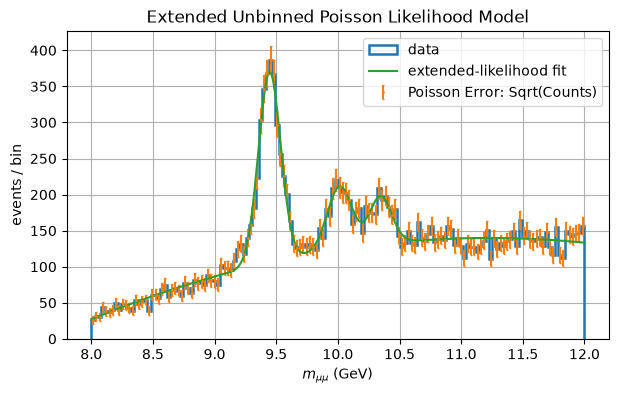

c1 = 0.5204176796315542
c2 = -0.21267281623815518
chi2 = 148.81778295868546
ndf = 138
reduced chi2 = 1.0783897315846773
p-value = 0.24991273732404343


In [65]:
fig, ax = plt.subplots(figsize=(7, 4))

mass_counts, mass_edges, _ = ax.hist(
    analysis_data["M_recomputed"],
    bins=150,
    histtype="step",
    lw=1.8,
    label="data",
)

mass_bin_width = mass_edges[1] - mass_edges[0]
mass_bin_centers = (mass_edges[:-1] + mass_edges[1:]) / 2

ax.errorbar(
    mass_bin_centers,
    mass_counts,
    yerr=np.sqrt(mass_counts),
    fmt="o",
    markersize=1,
    capsize=1,
    label='Poisson Error: Sqrt(Counts)',
)

ax.plot(
    mass_grid["M_recomputed"],
    mass_grid["fit_events_per_GeV"] * mass_bin_width,
    label="extended-likelihood fit",
)

ax.set_xlabel(r"$m_{\mu\mu}$ (GeV)")
ax.set_ylabel("events / bin")
ax.set_title("Extended Unbinned Poisson Likelihood Model")
ax.legend()
plt.savefig(FIGURE_DIR / "Likelihood_Intensity_Model.png", dpi=300, bbox_inches="tight")
plt.show()

fig.tight_layout()

print("c1 =", full_fit_parameters["background_cheb1"])
print("c2 =", full_fit_parameters["background_cheb2"])


### chi2 and p_value analysis ###

def normalized_residuals(parameters, model_function):
    prediction = model_function(mass_bin_centers, parameters) * mass_bin_width
    return (mass_counts - prediction) / np.sqrt(prediction)

residuals = normalized_residuals(
    full_fit_parameters,
    mass_projection_density,
)

chi2_value = np.sum(residuals**2)
n_parameters = len(full_fit_result.x)
ndf = len(mass_counts) - n_parameters

print(f"chi2 = {chi2_value}")
print(f"ndf = {ndf}")
print(f"reduced chi2 = {chi2_value / ndf}")
print(f"p-value = {chi2.sf(chi2_value, ndf)}")


- The reduced chi2 value near one supports the use of this model. One trait of a good fit is a chi2 value of approximatley one.
- The p-value indicates that it wouldn't be uncommon for repeated trials to get similar values for the chi2. This supports the case for this fit. 

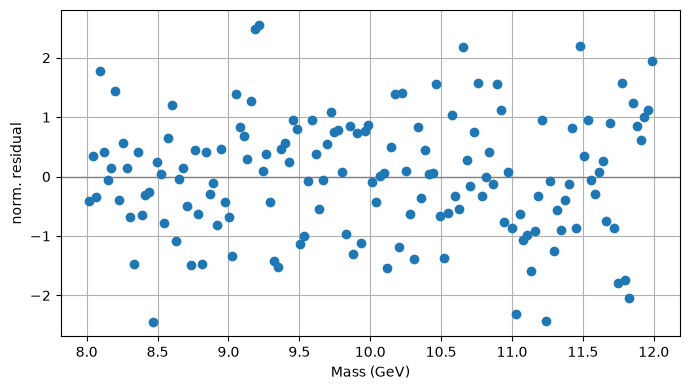

In [52]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.axhline(0.0, color="0.5", lw=1)
ax.errorbar(
    mass_bin_centers,
    residuals,
    fmt="o",
    capsize=3,
)
ax.set_xlabel("Mass (GeV)")
ax.set_ylabel("norm. residual")
fig.tight_layout()
plt.savefig(FIGURE_DIR / "Normalized_Residual.png", dpi=300, bbox_inches="tight")
plt.show()


- The plot of normalized residuals appears to randomly distrubited around zero in an even fashion. This shows no systematic change in the way the model predicts the number of events over the mass range. 
- The following likelihood-ration model comparison wil inform to what degree the signal contribution of the model improves the least likelihood

In [53]:
def unpack_background_parameters(transformed_parameters):
    """Convert transformed background-only parameters into physical values."""
    log_background_yield, background_cheb1, background_cheb2 = transformed_parameters
    return pd.Series(
        {
            "background_yield": np.exp(log_background_yield),
            "background_cheb1": background_cheb1,
            "background_cheb2": background_cheb2,
        }
    )

def background_only_intensity(data, transformed_parameters):
    """Evaluate the mass intensity for the background-only model."""
    parameters = unpack_background_parameters(transformed_parameters)
    mass_density = truncated_chebyshev_pdf(data["M_recomputed"], parameters["background_cheb1"],parameters["background_cheb2"], *MASS_RANGE)
    return parameters["background_yield"] * mass_density

def negative_log_likelihood_background(transformed_parameters, data=analysis_data):
    """Return the extended negative log-likelihood for the background-only model."""
    parameters = unpack_background_parameters(transformed_parameters)
    event_intensity = background_only_intensity(data, transformed_parameters)
    if np.any(event_intensity <= 0.0) or np.any(~np.isfinite(event_intensity)):
        return 1.0e30
    return parameters["background_yield"] - np.sum(np.log(event_intensity))

background_initial_parameters = np.array([np.log(len(analysis_data)), full_fit_parameters["background_cheb1"],full_fit_parameters["background_cheb2"]])

background_bounds = [(np.log(1.0), np.log(30000.0)),(0.0,0.8),(-1.0,1.0)]

background_fit_result = minimize(
    negative_log_likelihood_background,
    x0=background_initial_parameters,
    method="L-BFGS-B",
    bounds=background_bounds,
    options={"maxiter": 20000, "ftol": 1.0e-9},
)

# Display the fitted background-only parameters in physical units.
background_fit_parameters = unpack_background_parameters(background_fit_result.x)
print("background fit success:", background_fit_result.success)
background_fit_parameters.to_frame("estimate")

background fit success: True


,estimate
background_yield,20000.001348
background_cheb1,0.392561
background_cheb2,-0.472371


In [54]:
likelihood_ratio_statistic = 2 * (background_fit_result.fun - full_fit_result.fun)
delta_parameters = len(full_fit_result.x)-len(background_fit_result.x)
approximate_p_value = chi2.sf(likelihood_ratio_statistic,delta_parameters)

likelihood_ratio_table = pd.DataFrame([
    {
        "comparison": "signal + background vs background only",
        "q_delta_minus_2_log_L": likelihood_ratio_statistic,
        "delta_parameters": delta_parameters,
        "approximate_p_value": approximate_p_value,
        "caveat": "signal yield is bounded at zero; Wilks approximation is not exact",
    }
])
likelihood_ratio_table

,comparison,q_delta_minus_2_log_L,delta_parameters,approximate_p_value,caveat
0,signal + background vs background only,1869.233955,9,0.0,signal yield is bounded at zero; Wilks approxi...


- The large value of q means that there is a large difference in the least likehood fit between the model with peaks and the model with only background signal. Displaying how the signal + background improves the fit considerably from  a model with only background contributions. 

- a p value of zero says for a background only hypothesis. getting a chi^2 differnce this large between the background model and the signal is extrmeely improbable. This supports the supposition that the "background only" model is inadequate


- To get a sense of the uncertainty associated with each of the 12 variables assocaited with the fit, we perform a profile likelihood. The profile likelihood recalculates the best fit for that for some range of fixed signal yields. The signal yields for which the difference between the best fits is one, is one standard deviation of confidence in the signal yield parameter. 

In [73]:
def minimize_nuisance_parameters_for_signal_yield(fixed_signal_yield, starting_nuisance_parameters, signal_index):
    """Refit all non-signal-yield parameters at one fixed signal yield."""
    log_fixed_signal_yield = np.log(fixed_signal_yield)
    nuisance_bounds = full_parameter_bounds[:signal_index] + full_parameter_bounds[signal_index + 1:]

    # The optimizer sees only nuisance parameters; the signal yield is held fixed.
    def profile_objective(nuisance_parameters):
        transformed_parameters = np.insert(nuisance_parameters, signal_index, log_fixed_signal_yield)
        return negative_log_likelihood_full(transformed_parameters, analysis_data)

    return minimize(
        profile_objective,
        x0=starting_nuisance_parameters,
        method="L-BFGS-B",
        bounds=nuisance_bounds,
        options={"maxiter": 20000, "ftol": 1.0e-9},
    )


def crossing_points(x_values, y_values, level=1.0):
    """Find linear-interpolated x positions where y crosses a chosen level."""
    crossings = []
    for left_index in range(len(x_values) - 1):
        x1, x2 = x_values[left_index], x_values[left_index + 1]
        y1, y2 = y_values[left_index], y_values[left_index + 1]
        if (y1 - level) * (y2 - level) <= 0.0 and y1 != y2:
            crossings.append(x1 + (level - y1) * (x2 - x1) / (y2 - y1))
    return np.array(crossings)


best_signal_yields = [full_fit_parameters["signal_yield1"],full_fit_parameters["signal_yield2"],full_fit_parameters["signal_yield3"]]

# At each fixed signal yield, refit the nuisance parameters and store the profile curve.
profile_rows = []

for i in range(len(best_signal_yields)):

    best_signal_yield = best_signal_yields[i]

    # Scan outward from the best fit separately to the left and right.
    profile_signal_yield_grid_left = np.linspace(
        best_signal_yield,
        0.65 * best_signal_yield,
        23,
    )

    profile_signal_yield_grid_right = np.linspace(
        best_signal_yield,
        1.35 * best_signal_yield,
        23,
    )[1:]

    best_nuisance_start = np.delete(full_fit_result.x, i)

    current_nuisance_start = best_nuisance_start.copy()

    for fixed_signal_yield in profile_signal_yield_grid_left:

        profile_fit = minimize_nuisance_parameters_for_signal_yield(
            fixed_signal_yield,
            current_nuisance_start,
            i,
        )

        if profile_fit.success:
            current_nuisance_start = profile_fit.x

        transformed_parameters = np.insert(
            profile_fit.x,
            i,
            np.log(fixed_signal_yield),
        )

        profile_parameters = unpack_full_parameters(transformed_parameters)

        profile_rows.append(
            {
                "signal_number": i + 1,
                "signal_yield": fixed_signal_yield,
                "profile_nll": profile_fit.fun,
                "profile_q": 2.0 * (profile_fit.fun - full_fit_result.fun),
                "fit_success": profile_fit.success,
                "signal_yield1": profile_parameters["signal_yield1"],
                "signal_yield2": profile_parameters["signal_yield2"],
                "signal_yield3": profile_parameters["signal_yield3"],
                "background_yield": profile_parameters["background_yield"],
                "mass_mean1_GeV": profile_parameters["mass_mean1_GeV"],
                "mass_sigma1_GeV": profile_parameters["mass_sigma1_GeV"],
                "mass_mean2_GeV": profile_parameters["mass_mean2_GeV"],
                "mass_sigma2_GeV": profile_parameters["mass_sigma2_GeV"],
                "mass_mean3_GeV": profile_parameters["mass_mean3_GeV"],
                "mass_sigma3_GeV": profile_parameters["mass_sigma3_GeV"],
                "background_cheb1": profile_parameters["background_cheb1"],
                "background_cheb2": profile_parameters["background_cheb2"],
            }
        )

    current_nuisance_start = best_nuisance_start.copy()

    for fixed_signal_yield in profile_signal_yield_grid_right:

        profile_fit = minimize_nuisance_parameters_for_signal_yield(
            fixed_signal_yield,
            current_nuisance_start,
            i,
        )

        if profile_fit.success:
            current_nuisance_start = profile_fit.x

        transformed_parameters = np.insert(
            profile_fit.x,
            i,
            np.log(fixed_signal_yield),
        )

        profile_parameters = unpack_full_parameters(transformed_parameters)

        profile_rows.append(
            {
                "signal_number": i + 1,
                "signal_yield": fixed_signal_yield,
                "profile_nll": profile_fit.fun,
                "profile_q": 2.0 * (profile_fit.fun - full_fit_result.fun),
                "fit_success": profile_fit.success,
                "signal_yield1": profile_parameters["signal_yield1"],
                "signal_yield2": profile_parameters["signal_yield2"],
                "signal_yield3": profile_parameters["signal_yield3"],
                "background_yield": profile_parameters["background_yield"],
                "mass_mean1_GeV": profile_parameters["mass_mean1_GeV"],
                "mass_sigma1_GeV": profile_parameters["mass_sigma1_GeV"],
                "mass_mean2_GeV": profile_parameters["mass_mean2_GeV"],
                "mass_sigma2_GeV": profile_parameters["mass_sigma2_GeV"],
                "mass_mean3_GeV": profile_parameters["mass_mean3_GeV"],
                "mass_sigma3_GeV": profile_parameters["mass_sigma3_GeV"],
                "background_cheb1": profile_parameters["background_cheb1"],
                "background_cheb2": profile_parameters["background_cheb2"],
            }
        )


# Find the approximate 68% interval from the Delta q = 1 crossings.
profile_signal_yield = pd.DataFrame(profile_rows)
profile_uncertainty_rows = []

for i in range(len(best_signal_yields)):

    best_signal_yield = best_signal_yields[i]

    signal_profile = profile_signal_yield[
        profile_signal_yield["signal_number"] == i + 1
    ].sort_values("signal_yield")

    profile_crossings = crossing_points(
        signal_profile["signal_yield"].to_numpy(),
        signal_profile["profile_q"].to_numpy(),
        level=1.0,
    )

    lower_crossings = profile_crossings[profile_crossings < best_signal_yield]
    upper_crossings = profile_crossings[profile_crossings > best_signal_yield]

    profile_lower = lower_crossings.max() if len(lower_crossings) > 0 else np.nan
    profile_upper = upper_crossings.min() if len(upper_crossings) > 0 else np.nan

    profile_uncertainty_rows.append(
        {
            "parameter": f"signal_yield{i+1}",
            "estimate": best_signal_yield,
            "profile_lower_68": profile_lower,
            "profile_upper_68": profile_upper,
            "minus_uncertainty": best_signal_yield - profile_lower,
            "plus_uncertainty": profile_upper - best_signal_yield,
        }
    )


# Summarize the profile-likelihood interval in a compact table.
profile_uncertainty_summary = pd.DataFrame(profile_uncertainty_rows)
profile_uncertainty_summary



,parameter,estimate,profile_lower_68,profile_upper_68,minus_uncertainty,plus_uncertainty
0,signal_yield1,3552.128450,3465.523314,3635.780935,86.605136,83.652485
1,signal_yield2,1634.265485,1561.937898,1709.407142,72.327587,75.141657
2,signal_yield3,1801.038862,1732.859341,1869.739781,68.179520,68.700919


In [74]:
uncertainty = pd.DataFrame({
    "estimate" : profile_uncertainty_summary["estimate"],
    "+1 sigma" : profile_uncertainty_summary["profile_upper_68"] - profile_uncertainty_summary["estimate"],
    "-1 sigma" : profile_uncertainty_summary["estimate"] - profile_uncertainty_summary["profile_lower_68"],
})

uncertainty

,estimate,+1 sigma,-1 sigma
0,3552.128450,83.652485,86.605136
1,1634.265485,75.141657,72.327587
2,1801.038862,68.700919,68.179520


- This analysis produces the one standard deviation confidence interval around each of the signal yield parameters.
- It is work noting that the uncertainties are all between 40-100. However, the estimated count for the first peak is roughly 2.5x and 4x the estimate for the second and third peaks respectively, so our percent uncertainty for the estimate of the second and third peak is larger. 

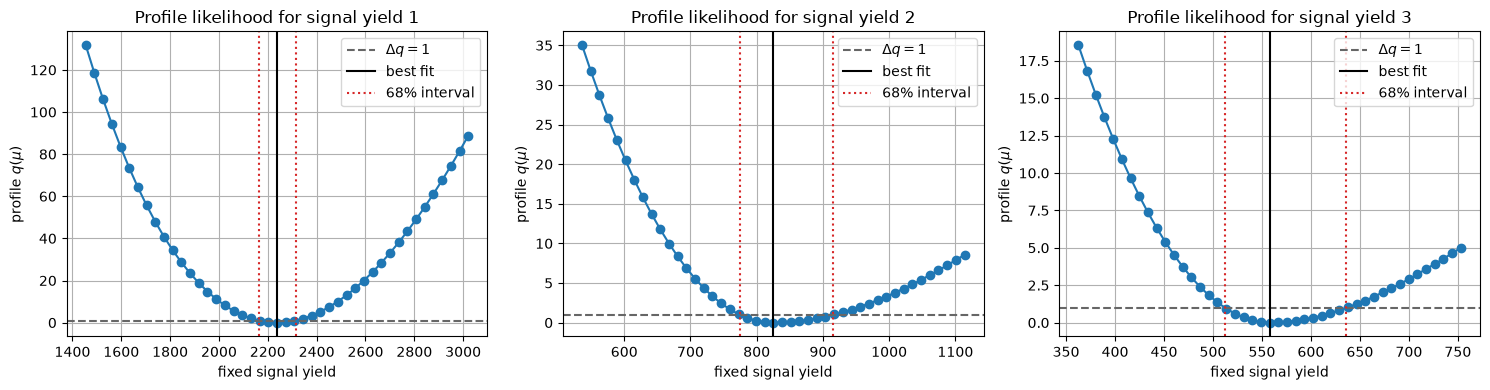

In [57]:

# Plot the profile-likelihood curve and mark the Delta q = 1 interval.
fig, axes = plt.subplots(1,3, figsize=(15, 4))

for i in range(len(best_signal_yields)):

    ax = axes[i]
    best_signal_yield = best_signal_yields[i]

    signal_profile = profile_signal_yield[
        profile_signal_yield["signal_number"] == i + 1
    ].sort_values("signal_yield")

    profile_lower = profile_uncertainty_summary["profile_lower_68"][i]
    profile_upper = profile_uncertainty_summary["profile_upper_68"][i]

    ax.plot(signal_profile["signal_yield"], signal_profile["profile_q"], "o-")
    ax.axhline(1.0, color="0.4", ls="--", label=r"$\Delta q=1$")
    ax.axvline(best_signal_yield, color="black", lw=1.5, label="best fit")
    ax.axvline(profile_lower, color="C3", ls=":", label="68% interval")
    ax.axvline(profile_upper, color="C3", ls=":")
    ax.set_xlabel("fixed signal yield")
    ax.set_ylabel(r"profile $q(\mu)$")
    ax.set_title(f"Profile likelihood for signal yield {i+1}")
    ax.legend()

fig.tight_layout()
plt.savefig(FIGURE_DIR / "Profile_Likelihood_Signal_Yields.png", dpi=300, bbox_inches="tight")
plt.show()

- We repeat the process evaluating the mass parameters instead of the best signal parameters. 

In [78]:
def minimize_nuisance_parameters_for_mass_mean(fixed_mass_mean, starting_nuisance_parameters, mass_index):
    """Refit all non-mass-mean parameters at one fixed mass mean."""
    nuisance_bounds = full_parameter_bounds[:mass_index] + full_parameter_bounds[mass_index + 1:]

    def profile_objective(nuisance_parameters):
        transformed_parameters = np.insert(nuisance_parameters, mass_index, fixed_mass_mean)
        return negative_log_likelihood_full(transformed_parameters, analysis_data)

    return minimize(
        profile_objective,
        x0=starting_nuisance_parameters,
        method="L-BFGS-B",
        bounds=nuisance_bounds,
        options={"maxiter": 20000, "ftol": 1.0e-9},
    )


best_mass_means = [
    full_fit_parameters["mass_mean1_GeV"],
    full_fit_parameters["mass_mean2_GeV"],
    full_fit_parameters["mass_mean3_GeV"],
]

mass_indices = [4,6,8]

profile_rows = []

for i in range(len(best_mass_means)):

    best_mass_mean = best_mass_means[i]
    mass_index = mass_indices[i]

    profile_mass_mean_grid_left = np.linspace(
        best_mass_mean,
        best_mass_mean - 0.1,
        30,
    )

    profile_mass_mean_grid_right = np.linspace(
        best_mass_mean,
        best_mass_mean + 0.5,
        30,
    )[1:]

    best_nuisance_start = np.delete(full_fit_result.x, mass_index)

    current_nuisance_start = best_nuisance_start.copy()

    for fixed_mass_mean in profile_mass_mean_grid_left:

        profile_fit = minimize_nuisance_parameters_for_mass_mean(
            fixed_mass_mean,
            current_nuisance_start,
            mass_index,
        )

        if profile_fit.success:
            current_nuisance_start = profile_fit.x

        transformed_parameters = np.insert(
            profile_fit.x,
            mass_index,
            fixed_mass_mean,
        )

        profile_parameters = unpack_full_parameters(transformed_parameters)

        profile_rows.append(
            {
                "signal_number": i + 1,
                "mass_mean": fixed_mass_mean,
                "profile_nll": profile_fit.fun,
                "profile_q": 2.0 * (profile_fit.fun - full_fit_result.fun),
                "fit_success": profile_fit.success,
                "signal_yield1": profile_parameters["signal_yield1"],
                "signal_yield2": profile_parameters["signal_yield2"],
                "signal_yield3": profile_parameters["signal_yield3"],
                "background_yield": profile_parameters["background_yield"],
                "mass_mean1_GeV": profile_parameters["mass_mean1_GeV"],
                "mass_sigma1_GeV": profile_parameters["mass_sigma1_GeV"],
                "mass_mean2_GeV": profile_parameters["mass_mean2_GeV"],
                "mass_sigma2_GeV": profile_parameters["mass_sigma2_GeV"],
                "mass_mean3_GeV": profile_parameters["mass_mean3_GeV"],
                "mass_sigma3_GeV": profile_parameters["mass_sigma3_GeV"],
                "background_cheb1": profile_parameters["background_cheb1"],
                "background_cheb2": profile_parameters["background_cheb2"],
            }
        )

    current_nuisance_start = best_nuisance_start.copy()

    for fixed_mass_mean in profile_mass_mean_grid_right:

        profile_fit = minimize_nuisance_parameters_for_mass_mean(
            fixed_mass_mean,
            current_nuisance_start,
            mass_index,
        )

        if profile_fit.success:
            current_nuisance_start = profile_fit.x

        transformed_parameters = np.insert(
            profile_fit.x,
            mass_index,
            fixed_mass_mean,
        )

        profile_parameters = unpack_full_parameters(transformed_parameters)

        profile_rows.append(
            {
                "signal_number": i + 1,
                "mass_mean": fixed_mass_mean,
                "profile_nll": profile_fit.fun,
                "profile_q": 2.0 * (profile_fit.fun - full_fit_result.fun),
                "fit_success": profile_fit.success,
                "signal_yield1": profile_parameters["signal_yield1"],
                "signal_yield2": profile_parameters["signal_yield2"],
                "signal_yield3": profile_parameters["signal_yield3"],
                "background_yield": profile_parameters["background_yield"],
                "mass_mean1_GeV": profile_parameters["mass_mean1_GeV"],
                "mass_sigma1_GeV": profile_parameters["mass_sigma1_GeV"],
                "mass_mean2_GeV": profile_parameters["mass_mean2_GeV"],
                "mass_sigma2_GeV": profile_parameters["mass_sigma2_GeV"],
                "mass_mean3_GeV": profile_parameters["mass_mean3_GeV"],
                "mass_sigma3_GeV": profile_parameters["mass_sigma3_GeV"],
                "background_cheb1": profile_parameters["background_cheb1"],
                "background_cheb2": profile_parameters["background_cheb2"],
            }
        )


profile_mass_mean = pd.DataFrame(profile_rows)
profile_uncertainty_rows = []

for i in range(len(best_mass_means)):

    best_mass_mean = best_mass_means[i]

    mass_profile = profile_mass_mean[
        profile_mass_mean["signal_number"] == i + 1
    ].sort_values("mass_mean")

    profile_crossings = crossing_points(
        mass_profile["mass_mean"].to_numpy(),
        mass_profile["profile_q"].to_numpy(),
        level=1.0,
    )

    lower_crossings = profile_crossings[profile_crossings < best_mass_mean]
    upper_crossings = profile_crossings[profile_crossings > best_mass_mean]

    profile_lower = lower_crossings.max() if len(lower_crossings) > 0 else np.nan
    profile_upper = upper_crossings.min() if len(upper_crossings) > 0 else np.nan

    profile_uncertainty_rows.append(
        {
            "parameter": f"mass_mean{i+1}_GeV",
            "estimate": best_mass_mean,
            "profile_lower_68": profile_lower,
            "profile_upper_68": profile_upper,
            "minus_uncertainty": best_mass_mean - profile_lower,
            "plus_uncertainty": profile_upper - best_mass_mean,
        }
    )


profile_uncertainty_summary = pd.DataFrame(profile_uncertainty_rows)
profile_uncertainty_summary


uncertainty = pd.DataFrame({
    "estimate" : profile_uncertainty_summary["estimate"],
    "+1 sigma" : profile_uncertainty_summary["profile_upper_68"] - profile_uncertainty_summary["estimate"],
    "-1 sigma" : profile_uncertainty_summary["estimate"] - profile_uncertainty_summary["profile_lower_68"],
})

uncertainty

,estimate,+1 sigma,-1 sigma
0,9.439331,0.000846,0.003692
1,9.990964,0.002430,0.006421
2,10.380000,0.464994,0.000728


- We perform the following parametric bootstrap as an estimate to the uncertainty present in each of the signal parameters. The method works by generating ficticious but plausible data sets. Our model is fitted to the ficticious data set and we evaluate the spread of our best fit parameters.  

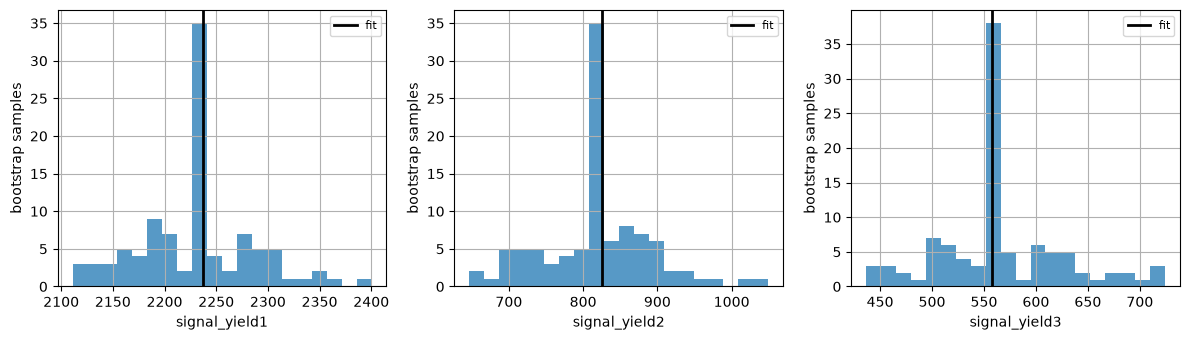

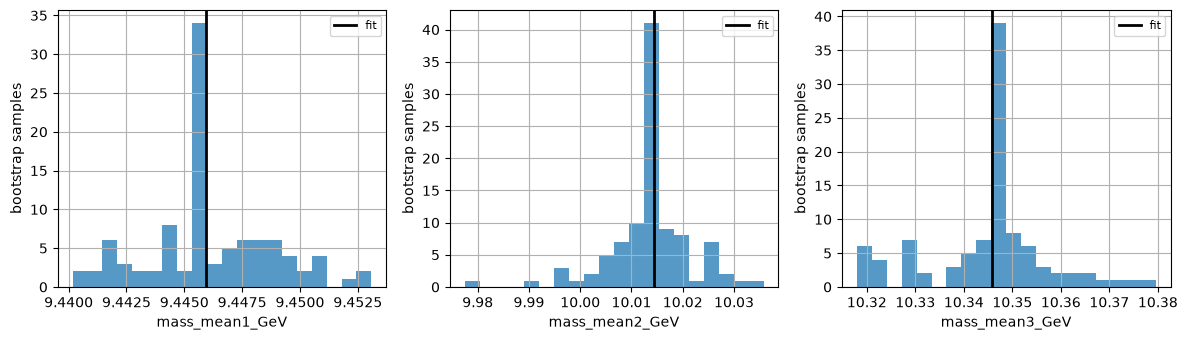

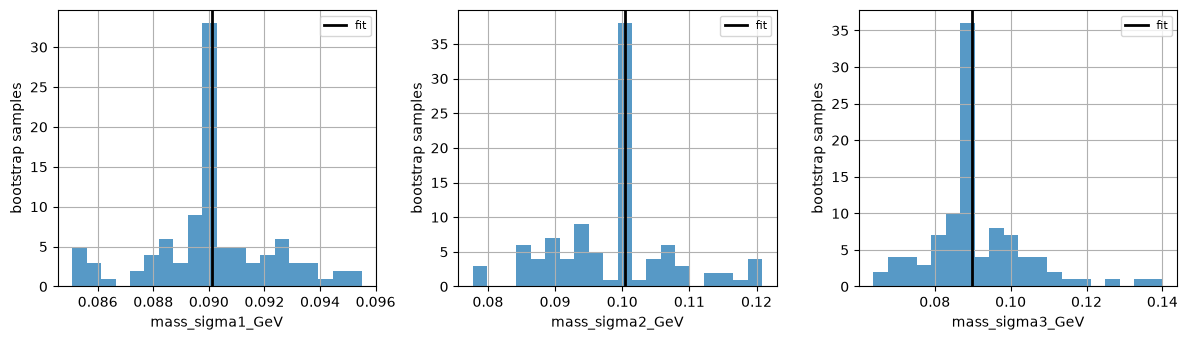

In [58]:
rng = np.random.default_rng(20260922)
def sample_cheby(size, coefficient1, coefficient2, lower, upper, rng):
    polynomial = np.polynomial.Chebyshev(
    [1.0, coefficient1, coefficient2],
    domain=[lower, upper],
    )

    x_grid = np.linspace(lower, upper, 1000)
    maximum = polynomial(x_grid).max()

    samples = []
    while len(samples) < size:
        proposal = rng.uniform(lower, upper, size=max(100, 2 * (size - len(samples))))
        ###
        proposal_test = rng.uniform(0, maximum, size=len(proposal))
        ###
        accepted = proposal[proposal_test <= polynomial(proposal)]
        samples.extend(accepted.tolist())

    return np.array(samples[:size])

def sample_truncated_gaussian(size, mean, sigma, lower, upper, rng):
    samples = []
    while len(samples) < size:
        proposal = rng.normal(mean, sigma, size=max(100, 2 * (size - len(samples))))
        accepted = proposal[(proposal >= lower) & (proposal <= upper)]
        samples.extend(accepted.tolist())

    return np.array(samples[:size])


def simulate_from_full_model(parameters, rng):
    n_model = (
        parameters["signal_yield1"]
        + parameters["signal_yield2"]
        + parameters["signal_yield3"]
        + parameters["background_yield"]
    )

    n_events = rng.poisson(n_model)

    signal1_probability = parameters["signal_yield1"] / n_model
    signal2_probability = parameters["signal_yield2"] / n_model
    signal3_probability = parameters["signal_yield3"] / n_model
    background_probability = parameters["background_yield"] / n_model

    component = rng.choice(
        4,
        size=n_events,
        p=[
            signal1_probability,
            signal2_probability,
            signal3_probability,
            background_probability,
        ],
    )

    simulated_mass = np.empty(n_events)

    is_signal1 = component == 0
    is_signal2 = component == 1
    is_signal3 = component == 2
    is_background = component == 3

    n_signal1 = int(is_signal1.sum())
    n_signal2 = int(is_signal2.sum())
    n_signal3 = int(is_signal3.sum())
    n_background = int(is_background.sum())

    simulated_mass[is_signal1] = sample_truncated_gaussian(
        n_signal1,
        parameters["mass_mean1_GeV"],
        parameters["mass_sigma1_GeV"],
        *MASS_RANGE,
        rng,
    )

    simulated_mass[is_signal2] = sample_truncated_gaussian(
        n_signal2,
        parameters["mass_mean2_GeV"],
        parameters["mass_sigma2_GeV"],
        *MASS_RANGE,
        rng,
    )

    simulated_mass[is_signal3] = sample_truncated_gaussian(
        n_signal3,
        parameters["mass_mean3_GeV"],
        parameters["mass_sigma3_GeV"],
        *MASS_RANGE,
        rng,
    )

    simulated_mass[is_background] = sample_cheby(
        n_background,
        parameters["background_cheb1"],
        parameters["background_cheb2"],
        *MASS_RANGE,
        rng,
    )

    return pd.DataFrame({"M_recomputed": simulated_mass})


def fit_full_model(data, starting_point=full_fit_result.x):
    return minimize(
        negative_log_likelihood_full,
        x0=starting_point,
        args=(data,),
        method="L-BFGS-B",
        bounds=full_parameter_bounds,
        options={"maxiter": 20000, "ftol": 1.0e-9},
    )


bootstrap_rows = []
number_of_bootstrap_samples = 100

for sample_index in range(number_of_bootstrap_samples):
    bootstrap_data = simulate_from_full_model(full_fit_parameters, rng)
    bootstrap_fit = fit_full_model(bootstrap_data)

    if not bootstrap_fit.success:
        continue

    bootstrap_parameters = unpack_full_parameters(bootstrap_fit.x)

    bootstrap_rows.append(
        {
            "sample": sample_index,
            **bootstrap_parameters.to_dict(),
        }
    )


bootstrap_results = pd.DataFrame(bootstrap_rows)

bootstrap_results.head()


bootstrap_columns_to_summarize = [
    "signal_yield1",
    "signal_yield2",
    "signal_yield3",
    "mass_mean1_GeV",
    "mass_mean2_GeV",
    "mass_mean3_GeV",
    "mass_sigma1_GeV",
    "mass_sigma2_GeV",
    "mass_sigma3_GeV",
]


bootstrap_summary_rows = []

for column in bootstrap_columns_to_summarize:
    values = bootstrap_results[column]

    bootstrap_summary_rows.append(
        {
            "parameter": column,
            "bootstrap_mean": values.mean(),
            "bootstrap_std": values.std(),
            "p16": values.quantile(0.16),
            "p84": values.quantile(0.84),
        }
    )


bootstrap_summary = pd.DataFrame(bootstrap_summary_rows)

bootstrap_summary


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for axis, column in zip(
    axes,
    ["signal_yield1", "signal_yield2", "signal_yield3"],
):

    axis.hist(bootstrap_results[column], bins=20, alpha=0.75)
    axis.axvline(full_fit_parameters[column], color="black", lw=2, label="fit")
    axis.set_xlabel(column)
    axis.set_ylabel("bootstrap samples")
    axis.legend(fontsize=8)

fig.tight_layout()


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for axis, column in zip(
    axes,
    ["mass_mean1_GeV", "mass_mean2_GeV", "mass_mean3_GeV"],
):

    axis.hist(bootstrap_results[column], bins=20, alpha=0.75)
    axis.axvline(full_fit_parameters[column], color="black", lw=2, label="fit")
    axis.set_xlabel(column)
    axis.set_ylabel("bootstrap samples")
    axis.legend(fontsize=8)

fig.tight_layout()


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for axis, column in zip(
    axes,
    ["mass_sigma1_GeV", "mass_sigma2_GeV", "mass_sigma3_GeV"],
):

    axis.hist(bootstrap_results[column], bins=20, alpha=0.75)
    axis.axvline(full_fit_parameters[column], color="black", lw=2, label="fit")
    axis.set_xlabel(column)
    axis.set_ylabel("bootstrap samples")
    axis.legend(fontsize=8)

fig.tight_layout()
plt.savefig(FIGURE_DIR / "Bootstrap Analysis.png", dpi=300, bbox_inches="tight")
plt.show()

- It's straightforward to see that in the majority of ficticous datasets, our model chooses the same parameters we had deterimed from the given data set. Some spread is present, however, particulalry in terms of the signal means, the value are spread over relatively small regions around the best fit signal. 